# 03. Machine-learning models (LightGBM, Random Forest, XGBoost)

One **global** model is trained on all stores at once, using the leak-safe features from notebook
01. Store identity and each store's recent history are features, so the model learns what the
stores have in common and how each one differs.

This notebook trains the models live on the final forecast window and then shows the results of
all three windows from the full pipeline.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


## 1. Train on everything before the final window, forecast the next 42 days

In [2]:
import time

from rossmann_forecast.cv import run_fold

t0 = time.time()
res = run_fold(panel, final_fold, prophet_stores=None, include_rf=True, keep_model=True, log=lambda *_: None)
preds = res.predictions
print(f"LightGBM, Random Forest and interval calibration fitted in {time.time() - t0:.0f} s")
print(f"{len(preds):,} scored store-days across {preds['store_id'].nunique():,} stores")
res.timings

LightGBM, Random Forest and interval calibration fitted in 63 s
40,282 scored store-days across 1,115 stores


{'lightgbm_fit': 15.439954000001308,
 'random_forest_fit': 29.490230499999598,
 'calibration_fit': 14.69531329999154}

XGBoost is added here as one more tree-ensemble on exactly the same rows and features, to compare
with the Random Forest and LightGBM (it is not part of the saved three-window results).

In [3]:
from xgboost import XGBRegressor

from rossmann_forecast.features import build_features, feature_columns
from rossmann_forecast.models import forecast_rows, training_rows

feats = build_features(panel, MIN_LAG, known_until=final_fold.test_start)
train = training_rows(feats, final_fold.test_start)
cols = feature_columns(train)
t0 = time.time()
xgb = XGBRegressor(n_estimators=500, learning_rate=0.06, max_depth=8, subsample=0.8, colsample_bytree=0.8,
                   tree_method="hist", random_state=42, n_jobs=-1)
xgb.fit(train[cols], np.log1p(train["sales"]))
xgb_seconds = time.time() - t0
test = forecast_rows(feats, final_fold.test_start, final_fold.test_end)
test = test[test["sales"].notna()]
xgb_pred = pd.Series(np.clip(np.expm1(xgb.predict(test[cols])), 0, None), index=test.index)
xgb_df = test[["date", "store_id"]].assign(xgboost=xgb_pred.values)
preds = preds.merge(xgb_df, on=["date", "store_id"], how="left")
print(f"XGBoost fitted in {xgb_seconds:.0f} s")

XGBoost fitted in 18 s


## 2. Accuracy in the final window

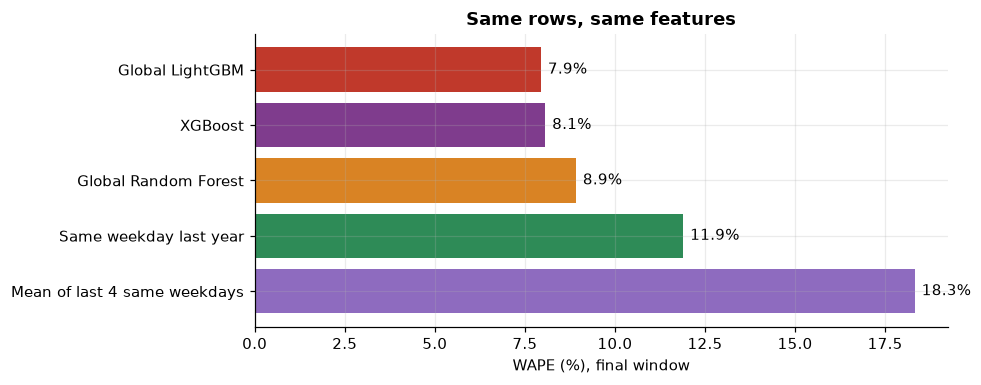

,WAPE %,RMSE,MAE,RMSPE
model,,,,
Mean of last 4 same weekdays,18.317,1698.393,1278.252,0.264
Same weekday last year,11.889,1235.234,829.713,0.174
Global Random Forest,8.910,928.120,621.788,0.129
XGBoost,8.058,832.417,562.339,0.116
Global LightGBM,7.939,827.732,554.017,0.114


In [4]:
models = ["snaive_mean4", "last_year", "random_forest", "xgboost", "lightgbm"]
label = {**NAMES, "xgboost": "XGBoost"}
rows = []
for m in models:
    v = preds.dropna(subset=[m])
    mm = all_metrics(v["y"], v[m])
    rows.append({"model": label[m], "WAPE %": mm["wape"] * 100, "RMSE": mm["rmse"], "MAE": mm["mae"], "RMSPE": mm["rmspe"]})
table = pd.DataFrame(rows).set_index("model").round(3)
colors = {**COLORS, "xgboost": "#7f3c8d"}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(table.index, table["WAPE %"], color=[colors[m] for m in models])
for i, v in enumerate(table["WAPE %"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center")
ax.set_xlabel("WAPE (%), final window")
ax.set_title("Same rows, same features")
fig.tight_layout()
plt.show()
table

The learned models roughly halve the error of the best naive rule. LightGBM, XGBoost and Random
Forest are close to each other; the gap to the baselines is far larger than the gap between them.

## 3. Predicted versus actual

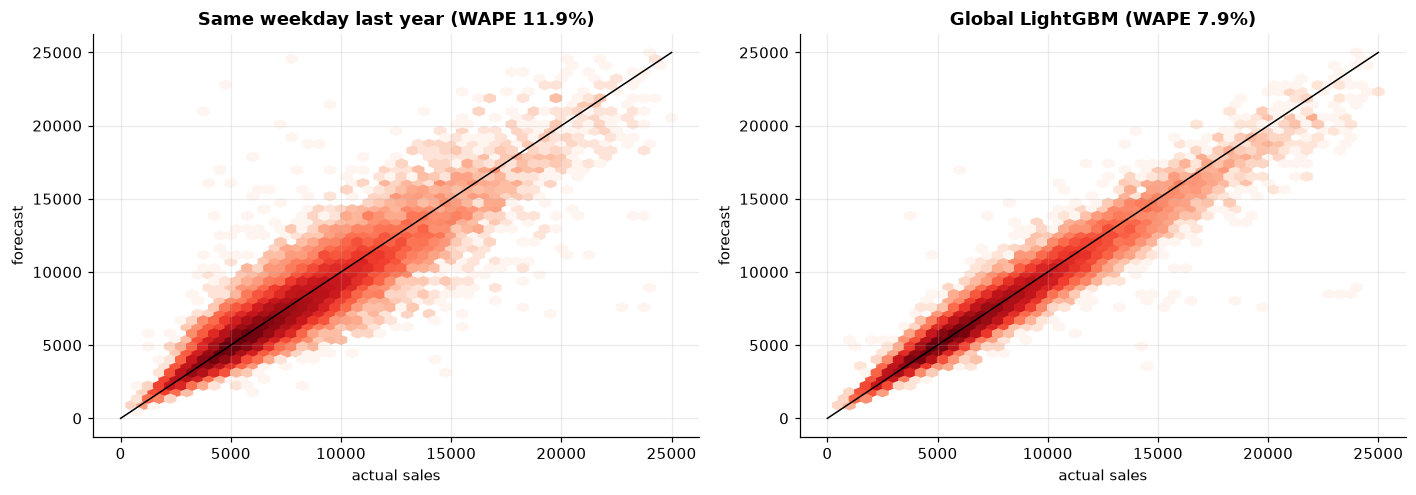

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, m in zip(axes, ["last_year", "lightgbm"], strict=True):
    v = preds.dropna(subset=[m])
    hb = ax.hexbin(v["y"], v[m], gridsize=50, bins="log", cmap="Reds", mincnt=1, extent=(0, 25000, 0, 25000))
    ax.plot([0, 25000], [0, 25000], color="black", lw=1)
    ax.set_xlabel("actual sales")
    ax.set_ylabel("forecast")
    ax.set_title(f"{label[m]} (WAPE {wape(v['y'], v[m]) * 100:.1f}%)")
fig.tight_layout()
plt.show()

## 4. Where the error comes from

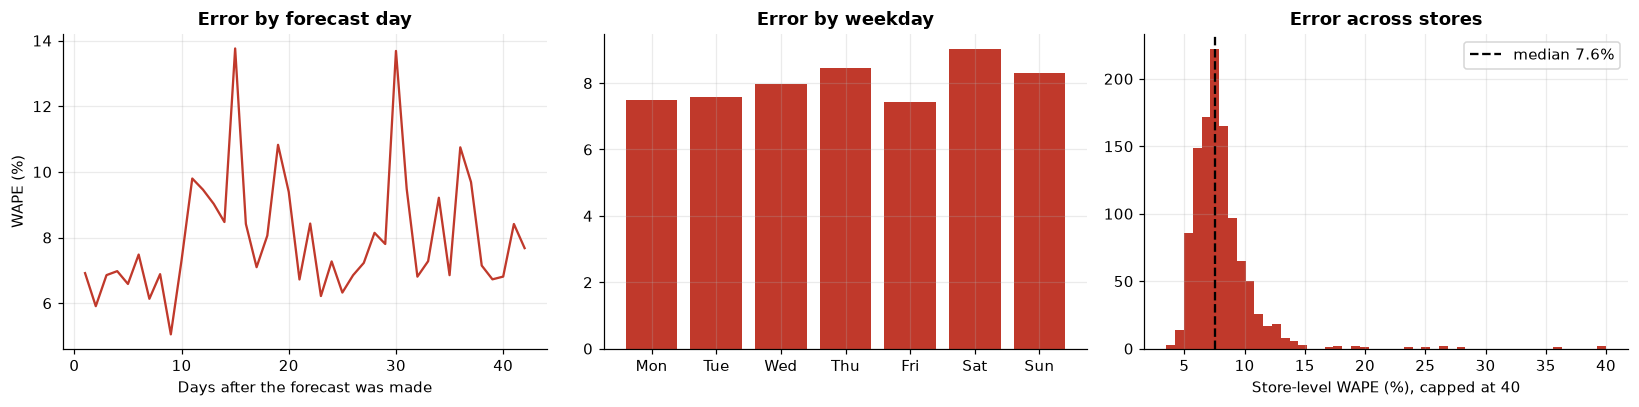

In [6]:
preds["abs_err"] = (preds["y"] - preds["lightgbm"]).abs()
preds["day"] = (preds["date"] - final_fold.test_start).dt.days + 1
preds["dow"] = preds["date"].dt.dayofweek
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
by_h = preds.groupby("day").apply(lambda g: wape(g["y"], g["lightgbm"]) * 100)
axes[0].plot(by_h.index, by_h.values, color=COLORS["lightgbm"])
axes[0].set_xlabel("Days after the forecast was made")
axes[0].set_ylabel("WAPE (%)")
axes[0].set_title("Error by forecast day")
by_d = preds.groupby("dow").apply(lambda g: wape(g["y"], g["lightgbm"]) * 100)
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_d.values, color=COLORS["lightgbm"])
axes[1].set_title("Error by weekday")
store_wape = preds.groupby("store_id").apply(lambda g: wape(g["y"], g["lightgbm"]) * 100)
axes[2].hist(store_wape.clip(upper=40), bins=50, color=COLORS["lightgbm"])
axes[2].axvline(store_wape.median(), color="black", ls="--", label=f"median {store_wape.median():.1f}%")
axes[2].set_xlabel("Store-level WAPE (%), capped at 40")
axes[2].set_title("Error across stores")
axes[2].legend()
fig.tight_layout()
plt.show()

The forecast does not get much worse day by day because the features are already at least 42 days
old for every target date. The histogram shows the tail: a few stores (often ones that just
reopened after a closure) are far harder than the median.

## 5. What the models use

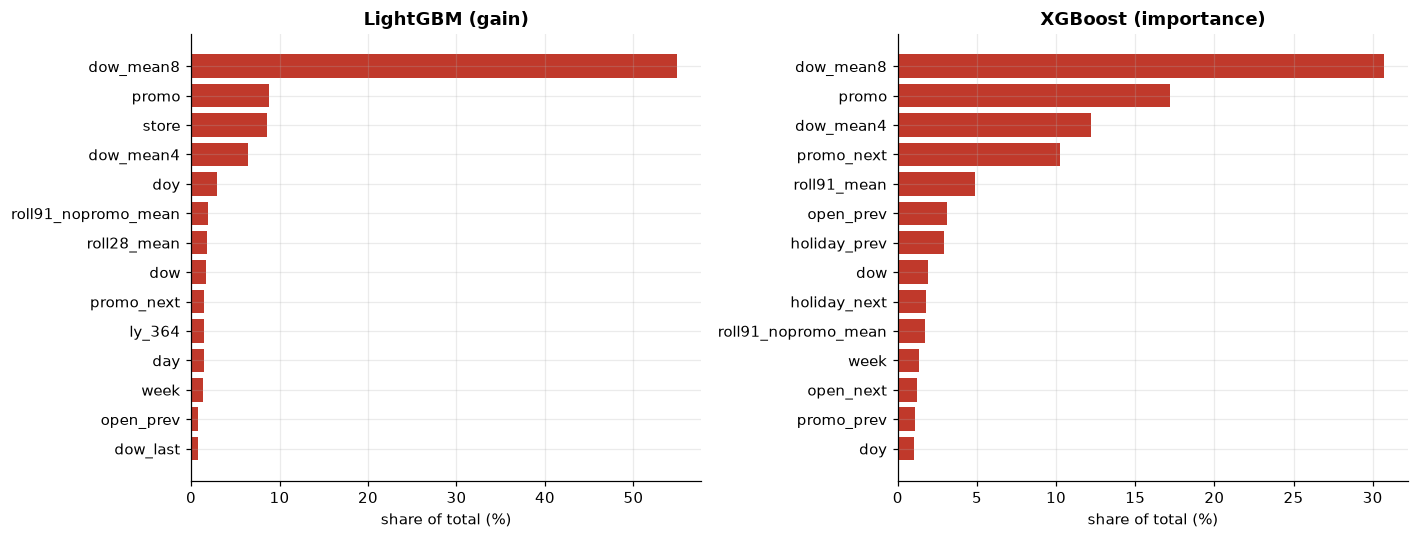

In [7]:
imp_l = pd.Series(res.lightgbm.model.booster_.feature_importance("gain"), index=res.lightgbm.columns)
imp_x = pd.Series(xgb.feature_importances_, index=cols)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, imp, name in zip(axes, [imp_l, imp_x], ["LightGBM (gain)", "XGBoost (importance)"], strict=True):
    top = (imp / imp.sum()).sort_values().tail(14)
    ax.barh(top.index, top.values * 100, color=COLORS["lightgbm"])
    ax.set_xlabel("share of total (%)")
    ax.set_title(name)
fig.tight_layout()
plt.show()

## 6. All three windows (saved pipeline results)

In [8]:
import json

results = json.loads((ROOT / "reports" / "results.json").read_text())
allm = results["all_stores"]
rows = []
for m in ["naive_last", "snaive", "snaive_mean4", "last_year", "random_forest", "lightgbm"]:
    e = allm[m]
    rows.append({
        "model": NAMES[m],
        **{f"WAPE window {pf['fold']}": f"{pf['wape'] * 100:.1f}%" for pf in e["per_fold"]},
        "WAPE mean +/- std": f"{e['mean']['wape'] * 100:.1f}% +/- {e['std']['wape'] * 100:.1f}",
        "RMSE mean": f"{e['mean']['rmse']:,.0f}",
    })
pd.DataFrame(rows).set_index("model")

,WAPE window 1,WAPE window 2,WAPE window 3,WAPE mean +/- std,RMSE mean
model,,,,,
Naive (last day),35.8%,30.0%,23.3%,29.7% +/- 6.3,"2,791"
Seasonal naive (last week),24.3%,23.1%,21.3%,22.9% +/- 1.5,"2,247"
Mean of last 4 same weekdays,16.6%,21.7%,18.3%,18.9% +/- 2.6,"1,868"
Same weekday last year,29.9%,16.0%,11.9%,19.3% +/- 9.5,"1,986"
Global Random Forest,9.0%,13.3%,8.9%,10.4% +/- 2.5,"1,178"
Global LightGBM,7.6%,12.1%,7.9%,9.2% +/- 2.5,"1,020"


In [9]:
timing = pd.DataFrame(results["timing_seconds"]).T
timing = timing.rename(columns={
    "lightgbm_fit": "LightGBM, all stores (s)", "random_forest_fit": "Random Forest, all stores (s)",
    "prophet_plain_fit_per_store": "Prophet, per store (s)", "prophet_promo_fit_per_store": "Prophet + regressors, per store (s)",
    "calibration_fit": "calibration refit (s)"})
timing.round(2)

,"LightGBM, all stores (s)","Random Forest, all stores (s)",calibration refit (s),"Prophet, per store (s)","Prophet + regressors, per store (s)"
fold1,12.68,16.57,11.72,0.67,0.53
fold2,14.46,25.55,15.46,0.44,0.48
fold3,18.35,33.43,17.21,0.44,0.45


One LightGBM fit covers every store and takes seconds. Prophet needs a separate fit for each
store, so fitting all stores would cost over a thousand fits per window. The next notebook adds
uncertainty to these forecasts.